In [62]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.impute import SimpleImputer

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [63]:



df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (284807, 31)


In [64]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [66]:

df.isnull().sum()


,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [67]:

df.duplicated().sum()


np.int64(1081)

In [68]:

df["Class"].value_counts()


,count
Class,
0,284315
1,492


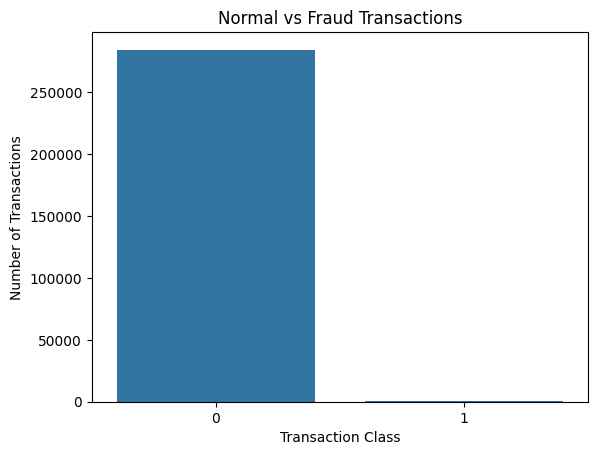

In [69]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Class")

plt.title("Normal vs Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()


In [70]:

df["Amount"].describe()


,Amount
count,284807.000000
mean,88.349619
std,250.120109
min,0.000000
25%,5.600000
50%,22.000000
75%,77.165000
max,25691.160000


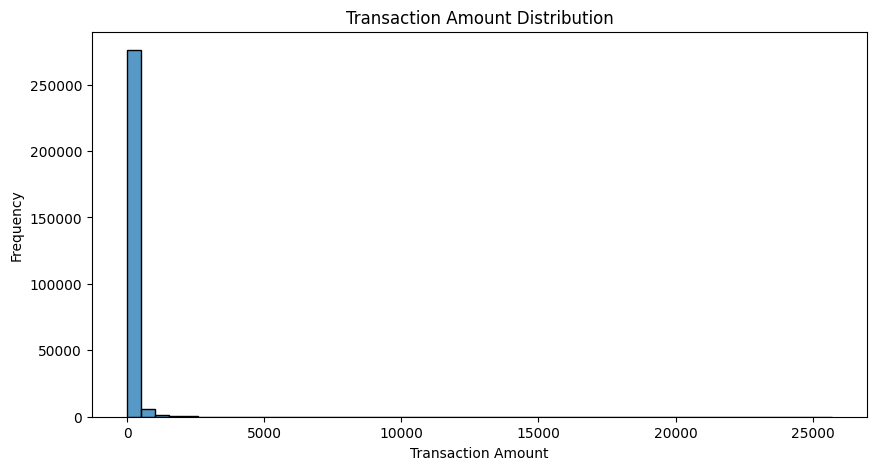

In [71]:

plt.figure(figsize=(10, 5))

sns.histplot(df["Amount"], bins=50)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()


In [72]:

df["Amount"].skew()


np.float64(16.977724453761006)

In [73]:

import numpy as np

original_skew = df["Amount"].skew()

log_amount = np.log1p(df["Amount"])
log_skew = log_amount.skew()

print("Original Skewness:", original_skew)
print("After Log Skewness:", log_skew)


Original Skewness: 16.977724453761006
After Log Skewness: 0.16270292774164008


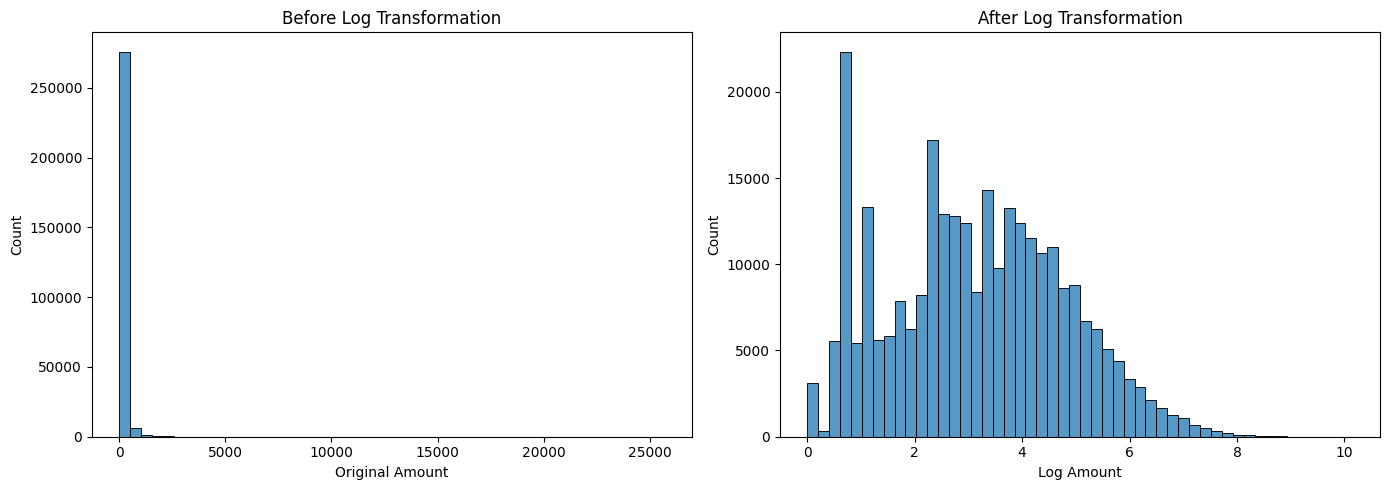

In [74]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original Amount
sns.histplot(df["Amount"], bins=50, ax=axes[0])
axes[0].set_title("Before Log Transformation")
axes[0].set_xlabel("Original Amount")

# Log Transformed Amount
sns.histplot(log_amount, bins=50, ax=axes[1])
axes[1].set_title("After Log Transformation")
axes[1].set_xlabel("Log Amount")

plt.tight_layout()
plt.show()


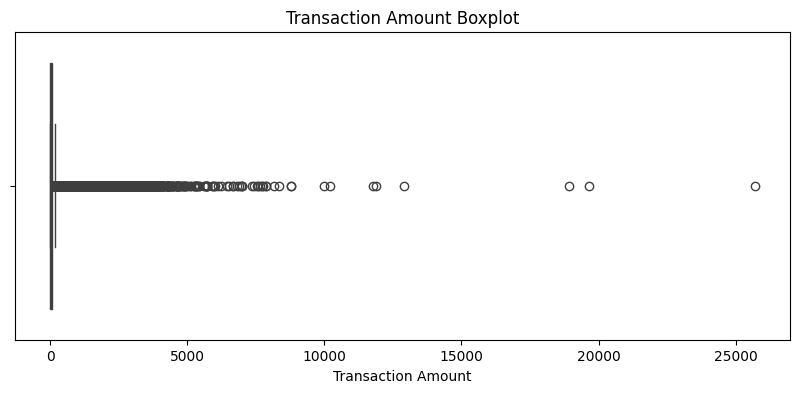

In [75]:


plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Amount"])

plt.title("Transaction Amount Boxplot")
plt.xlabel("Transaction Amount")

plt.show()


In [76]:

Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["Amount"] < lower) |
    (df["Amount"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Boundary:", lower)
print("Upper Boundary:", upper)
print("Total Outliers:", len(outliers))


Q1: 5.6
Q3: 77.16499999999999
IQR: 71.565
Lower Boundary: -101.7475
Upper Boundary: 184.5125
Total Outliers: 31904


In [77]:

outliers["Class"].value_counts()


,count
Class,
0,31813
1,91


In [78]:

df.groupby("Class")["Amount"].describe()


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


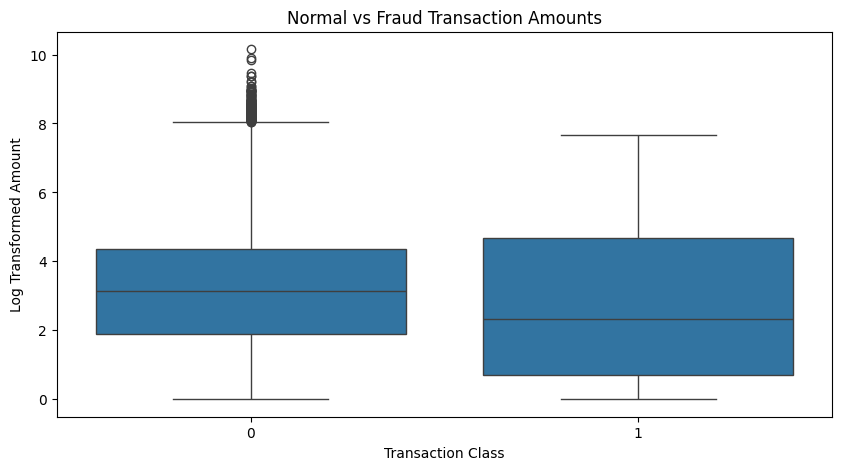

In [79]:

# EDA  temporary column
df["Log_Amount"] = np.log1p(df["Amount"])

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Log_Amount"
)

plt.title("Normal vs Fraud Transaction Amounts")
plt.xlabel("Transaction Class")
plt.ylabel("Log Transformed Amount")

plt.show()



In [80]:

df["Time"].describe()


,Time
count,284807.000000
mean,94813.859575
std,47488.145955
min,0.000000
25%,54201.500000
50%,84692.000000
75%,139320.500000
max,172792.000000


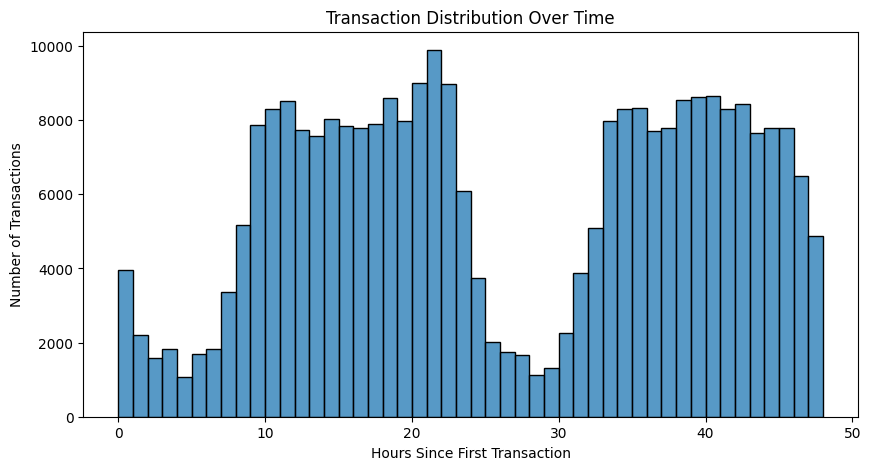

In [81]:

plt.figure(figsize=(10, 5))

sns.histplot(df["Time"] / 3600, bins=48)

plt.title("Transaction Distribution Over Time")
plt.xlabel("Hours Since First Transaction")
plt.ylabel("Number of Transactions")

plt.show()


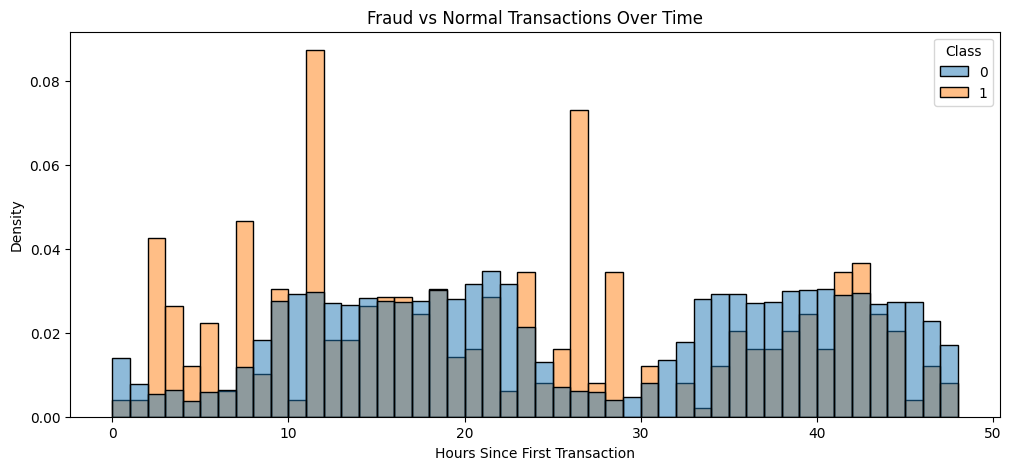

In [82]:

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x=df["Time"] / 3600,
    hue="Class",
    bins=48,
    multiple="layer",
    stat="density",
    common_norm=False,
    alpha=0.5
)

plt.title("Fraud vs Normal Transactions Over Time")
plt.xlabel("Hours Since First Transaction")
plt.ylabel("Density")

plt.show()


In [83]:

correlation = df.corr(numeric_only=True)

fraud_correlation = correlation["Class"]

fraud_correlation = fraud_correlation.drop("Class")

fraud_correlation = fraud_correlation.sort_values()

print(fraud_correlation)


V17          -0.326481
V14          -0.302544
V12          -0.260593
V10          -0.216883
V16          -0.196539
V3           -0.192961
V7           -0.187257
V18          -0.111485
V1           -0.101347
V9           -0.097733
V5           -0.094974
V6           -0.043643
Time         -0.012323
Log_Amount   -0.008326
V24          -0.007221
V13          -0.004570
V15          -0.004223
V23          -0.002685
V22           0.000805
V25           0.003308
V26           0.004455
Amount        0.005632
V28           0.009536
V27           0.017580
V8            0.019875
V20           0.020090
V19           0.034783
V21           0.040413
V2            0.091289
V4            0.133447
V11           0.154876
Name: Class, dtype: float64


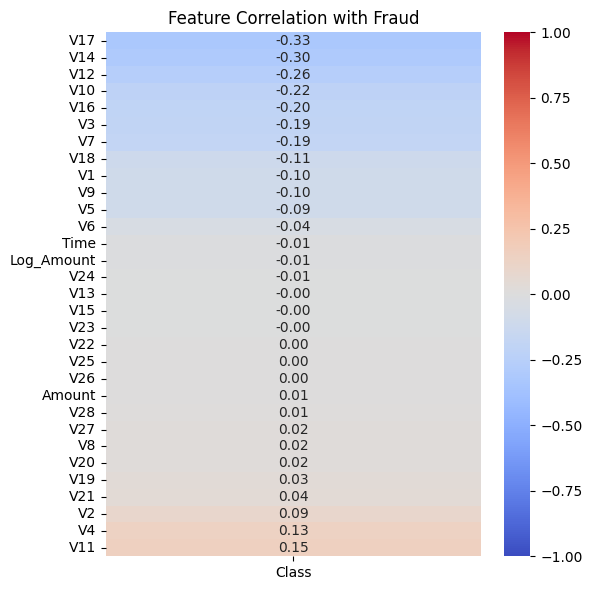

In [84]:

plt.figure(figsize=(6, 6))

sns.heatmap(
    fraud_correlation.to_frame(),
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Feature Correlation with Fraud")
plt.tight_layout()
plt.show()


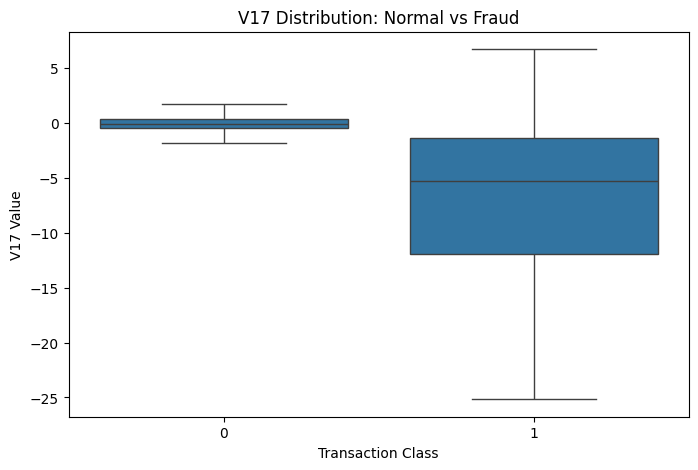

In [85]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="V17",
    showfliers=False
)

plt.title("V17 Distribution: Normal vs Fraud")
plt.xlabel("Transaction Class")
plt.ylabel("V17 Value")

plt.show()


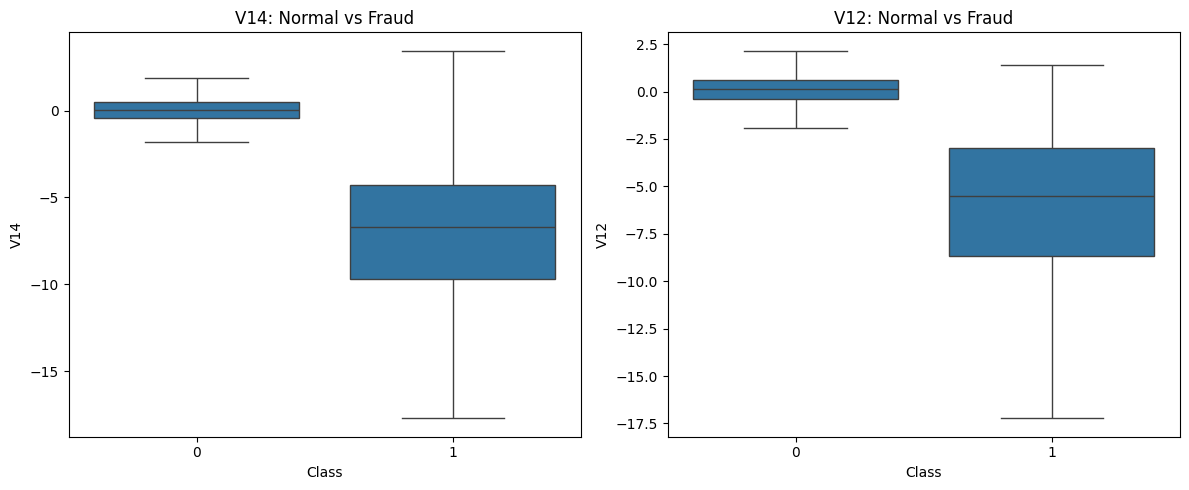

In [86]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="V14",
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title("V14: Normal vs Fraud")

sns.boxplot(
    data=df,
    x="Class",
    y="V12",
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title("V12: Normal vs Fraud")

plt.tight_layout()
plt.show()


In [87]:

X = df.drop(columns=["Class", "Log_Amount"])

y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (284807, 30)
Target shape: (284807,)


In [88]:
from sklearn.model_selection import train_test_split

# Drop rows with NaN values to prevent train_test_split or models from failing
df_cleaned = df.dropna(subset=["Class"])

X = df_cleaned.drop(columns=["Class", "Log_Amount"])
y = df_cleaned["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (227845, 30)
Testing Features: (56962, 30)
Training Target: (227845,)
Testing Target: (56962,)


In [89]:

print("Training Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

print("\nTraining Fraud Percentage:")
print(y_train.mean() * 100)

print("\nTesting Fraud Percentage:")
print(y_test.mean() * 100)


Training Class Distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing Class Distribution:
Class
0    56864
1       98
Name: count, dtype: int64

Training Fraud Percentage:
0.17292457591783889

Testing Fraud Percentage:
0.17204452090867595


In [90]:

X_train_fe = X_train.copy()

X_train_fe["Log_Amount"] = np.log1p(
    X_train_fe["Amount"]
)

print("Original Training Shape:", X_train.shape)

print("New Training Shape:", X_train_fe.shape)

X_train_fe[["Amount", "Log_Amount"]].head()


Original Training Shape: (227845, 30)
New Training Shape: (227845, 31)


,Amount,Log_Amount
265518,7.32,2.118662
180305,2.99,1.383791
42664,175.10,5.171052
198723,6.10,1.960095
82325,86.10,4.467057


In [91]:

X_train_fe["Elapsed_Hours"] = (
    X_train_fe["Time"] / 3600
)

print("New Dataset Shape:", X_train_fe.shape)

display(
    X_train_fe[
        ["Time", "Elapsed_Hours", "Amount", "Log_Amount"]
    ].head()
)


New Dataset Shape: (227845, 32)


,Time,Elapsed_Hours,Amount,Log_Amount
265518,161919.0,44.977500,7.32,2.118662
180305,124477.0,34.576944,2.99,1.383791
42664,41191.0,11.441944,175.10,5.171052
198723,132624.0,36.840000,6.10,1.960095
82325,59359.0,16.488611,86.10,4.467057


In [92]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_fe["Scaled_Log_Amount"] = scaler.fit_transform(
    X_train_fe[["Log_Amount"]]
).ravel()

display(
    X_train_fe[
        ["Amount", "Log_Amount", "Scaled_Log_Amount"]
    ].head()
)


,Amount,Log_Amount,Scaled_Log_Amount
265518,7.32,2.118662,-0.624639
180305,2.99,1.383791,-1.068403
42664,175.10,5.171052,1.218601
198723,6.10,1.960095,-0.720392
82325,86.10,4.467057,0.793481


In [93]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler
)

# Amount pipeline
amount_pipeline = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scale", StandardScaler())
])

# Different columns processing
preprocessor = ColumnTransformer([
    ("amount", amount_pipeline, ["Amount"]),
    ("time", StandardScaler(), ["Time"])
], remainder="passthrough")

print("Preprocessing pipeline created!")
X_train

Preprocessing pipeline created!


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
265518,161919.0,1.946747,-0.752526,-1.355130,-0.661630,1.502822,4.024933,-1.479661,1.139880,1.406819,-0.157403,-0.113729,0.510277,0.061258,-0.066555,1.328702,0.352514,-0.765670,0.141938,-0.451365,-0.134435,0.076197,0.297537,0.307915,0.690980,-0.350316,-0.388907,0.077641,-0.032248,7.32
180305,124477.0,2.035149,-0.048880,-3.058693,0.247945,2.943487,3.298697,-0.002192,0.674782,0.045826,0.284864,-0.254903,0.325560,-0.405327,0.721068,-0.148445,-0.754029,-0.270842,-0.695698,-0.274411,-0.227279,0.038628,0.228197,0.035542,0.707090,0.512885,-0.471198,0.002520,-0.069002,2.99
42664,41191.0,-0.991920,0.603193,0.711976,-0.992425,-0.825838,1.956261,-2.212603,-5.037523,0.000772,-2.009561,-0.386845,1.820161,0.747777,0.122746,-1.723285,1.123344,-0.724616,0.147255,0.004631,1.280856,-2.798352,0.109526,-0.436530,-0.932803,0.826684,0.913773,0.038049,0.185340,175.10
198723,132624.0,2.285718,-1.500239,-0.747565,-1.668119,-1.394143,-0.350339,-1.427984,0.010010,-1.118447,1.756121,0.093136,-0.722450,-0.468757,-0.195288,-0.638683,-0.065888,0.072781,0.768237,0.257424,-0.490642,-0.139670,0.077013,0.208310,-0.538236,-0.278032,-0.162068,0.018045,-0.063005,6.10
82325,59359.0,-0.448747,-1.011440,0.115903,-3.454854,0.715771,-0.147490,0.504347,-0.113817,-0.044782,-0.558955,-0.251076,-0.054708,-0.782698,0.134659,-0.483007,-2.096099,-0.399525,1.597589,-0.082746,-0.275297,-0.243245,-0.173298,-0.006692,-1.362383,-0.292234,-0.144622,-0.032580,-0.064194,86.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233802,147710.0,1.993864,-0.516866,-0.620118,0.129845,-0.285128,0.395044,-0.822358,0.231591,0.995898,0.212619,0.319897,0.584204,-0.251486,0.062302,0.013795,0.684356,-0.906442,0.739436,0.043943,-0.174051,0.262526,0.884510,0.099141,0.275689,-0.195404,0.623598,-0.032455,-0.058552,5.99
85418,60764.0,-1.497933,0.657921,1.581568,-0.024286,0.584698,1.303031,0.609212,0.135561,0.452745,0.108640,0.521818,0.373473,-0.533295,-0.401809,0.771781,-1.879937,1.241541,-2.623211,-1.241768,-0.225079,-0.072452,0.299172,0.110048,-0.615980,-0.425883,0.263968,-0.448445,0.045178,36.99
29062,35301.0,1.069777,0.072105,0.496540,1.505318,-0.380277,-0.370243,0.100551,-0.026687,0.319684,-0.131553,-0.305690,0.445453,-0.547450,0.166727,-0.073930,-0.796913,0.404795,-1.033061,-0.500426,-0.149402,-0.061991,-0.044629,-0.050485,0.400171,0.593314,-0.335160,0.031014,0.024886,45.42
13766,24413.0,1.280465,0.300586,0.333044,0.512720,0.065052,-0.145844,-0.145519,-0.091833,1.111187,-0.268878,1.708922,-1.666023,2.119731,1.799882,-0.357245,0.705997,-0.247970,0.483059,0.278512,-0.093783,-0.409934,-0.961351,0.033153,-0.560429,0.278428,0.089546,-0.059835,-0.005887,0.89


In [94]:

X_train_processed = preprocessor.fit_transform(X_train)

print("Original Shape:", X_train.shape)
print("Processed Shape:", X_train_processed.shape)

print("\nFirst 5 processed rows:")
print(X_train_processed[:5, :5])


Original Shape: (227845, 30)
Processed Shape: (227845, 30)

First 5 processed rows:
[[-0.62463851  1.41158751  1.94674667 -0.75252582 -1.35512953]
 [-1.06840342  0.62314085  2.03514919 -0.04888031 -3.05869345]
 [ 1.2186012  -1.13068022 -0.99191964  0.60319264  0.71197602]
 [-0.72039229  0.79469886  2.28571782 -1.50023928 -0.74756516]
 [ 0.79348125 -0.74810186 -0.44874695 -1.01144002  0.11590267]]


In [95]:

print("Scaled Amount Mean:",
      X_train_processed[:, 0].mean())

print("Scaled Amount Standard Deviation:",
      X_train_processed[:, 0].std())

print("Scaled Time Mean:",
      X_train_processed[:, 1].mean())

print("Scaled Time Standard Deviation:",
      X_train_processed[:, 1].std())


Scaled Amount Mean: -8.133140752978302e-17
Scaled Amount Standard Deviation: 1.0
Scaled Time Mean: -1.409578075286117e-16
Scaled Time Standard Deviation: 0.9999999999999999


In [96]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

fraud_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

print("Fraud detection model pipeline created!")


Fraud detection model pipeline created!


In [97]:

fraud_model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [98]:

train_predictions = fraud_model.predict(X_train)

print("First 20 Predictions:")
print(train_predictions[:20])

print("\nPrediction Counts:")
print(pd.Series(train_predictions).value_counts())


First 20 Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Prediction Counts:
0    221963
1      5882
Name: count, dtype: int64


Confusion Matrix:
[[221935   5516]
 [    28    366]]


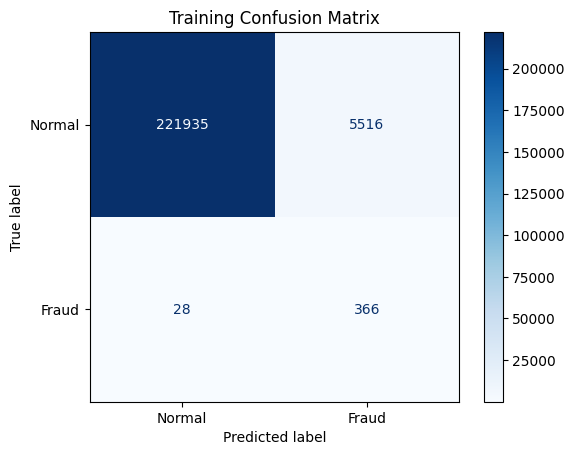

In [99]:

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_train, train_predictions)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
).plot(cmap="Blues")

plt.title("Training Confusion Matrix")
plt.show()


In [100]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_train,
        train_predictions,
        target_names=["Normal", "Fraud"]
    )
)


              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99    227451
       Fraud       0.06      0.93      0.12       394

    accuracy                           0.98    227845
   macro avg       0.53      0.95      0.55    227845
weighted avg       1.00      0.98      0.99    227845



In [101]:

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training Shape:", X_train_final.shape)
print("Validation Shape:", X_val.shape)

print("\nTraining Fraud Count:")
print(y_train_final.value_counts())

print("\nValidation Fraud Count:")
print(y_val.value_counts())


Training Shape: (182276, 30)
Validation Shape: (45569, 30)

Training Fraud Count:
Class
0    181961
1       315
Name: count, dtype: int64

Validation Fraud Count:
Class
0    45490
1       79
Name: count, dtype: int64


In [102]:

from sklearn.base import clone

validation_model = clone(fraud_model)

validation_model.fit(X_train_final, y_train_final)

print("Validation model trained successfully!")


Validation model trained successfully!


In [103]:

val_predictions = validation_model.predict(X_val)

print("First 20 Validation Predictions:")
print(val_predictions[:20])

print("\nValidation Prediction Counts:")
print(pd.Series(val_predictions).value_counts())


First 20 Validation Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Validation Prediction Counts:
0    44381
1     1188
Name: count, dtype: int64


Validation Confusion Matrix:
[[44371  1119]
 [   10    69]]


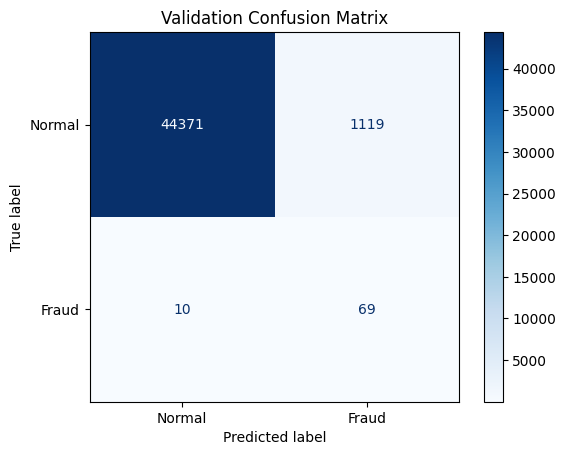

In [104]:

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

val_cm = confusion_matrix(
    y_val,
    val_predictions
)

print("Validation Confusion Matrix:")
print(val_cm)

ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=["Normal", "Fraud"]
).plot(cmap="Blues")

plt.title("Validation Confusion Matrix")
plt.show()


In [105]:

from sklearn.metrics import average_precision_score

val_probabilities = validation_model.predict_proba(X_val)[:, 1]

pr_auc = average_precision_score(
    y_val,
    val_probabilities
)

print("Validation Average Precision:", pr_auc)


Validation Average Precision: 0.6822373585615243


In [106]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.50, 0.70, 0.90, 0.95, 0.99]

results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Fraud Alerts": predictions.sum()
    })

threshold_results = pd.DataFrame(results)

display(threshold_results)


,Threshold,Precision,Recall,F1,Fraud Alerts
0,0.50,0.058081,0.873418,0.108919,1188
1,0.70,0.115059,0.860759,0.202985,591
2,0.90,0.212625,0.810127,0.336842,301
3,0.95,0.292237,0.810127,0.429530,219
4,0.99,0.543860,0.784810,0.642487,114


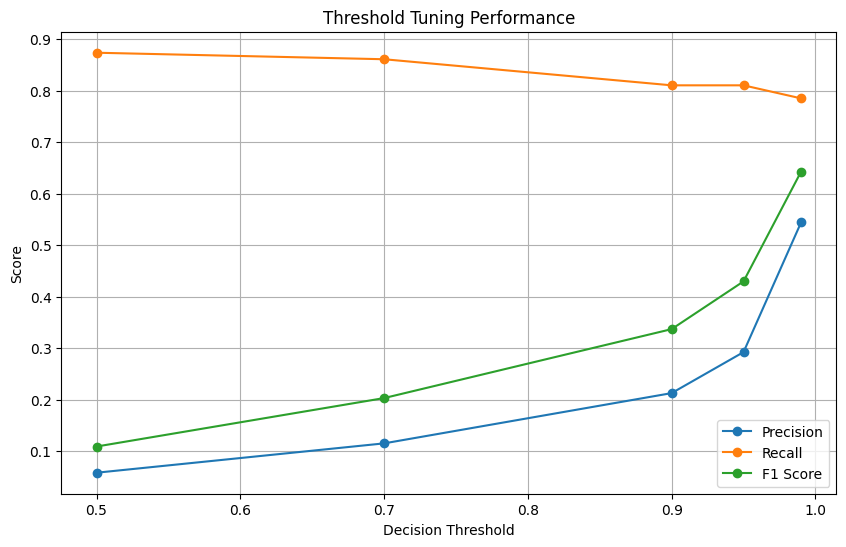

In [107]:

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1 Score"
)

plt.title("Threshold Tuning Performance")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)

plt.show()


In [108]:

high_thresholds = [
    0.99,
    0.992,
    0.995,
    0.997,
    0.999,
    0.9995
]

high_results = []

for threshold in high_thresholds:

    preds = (val_probabilities >= threshold).astype(int)

    high_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_val, preds, zero_division=0
        ),
        "F1": f1_score(
            y_val, preds, zero_division=0
        ),
        "Fraud Alerts": preds.sum()
    })

high_threshold_results = pd.DataFrame(high_results)

display(high_threshold_results)


,Threshold,Precision,Recall,F1,Fraud Alerts
0,0.9900,0.543860,0.78481,0.642487,114
1,0.9920,0.563636,0.78481,0.656085,110
2,0.9950,0.601942,0.78481,0.681319,103
3,0.9970,0.613861,0.78481,0.688889,101
4,0.9990,0.681319,0.78481,0.729412,91
5,0.9995,0.688889,0.78481,0.733728,90


In [109]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

rf_preprocessor = ColumnTransformer(
    transformers=[
        ("features", "passthrough", X_train_final.columns.tolist())
    ]
)

rf_model = Pipeline([
    ("preprocessing", rf_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created!")


Random Forest pipeline created!


In [110]:

rf_model.fit(X_train_final, y_train_final)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [111]:

rf_val_predictions = rf_model.predict(X_val)

rf_val_probabilities = rf_model.predict_proba(X_val)[:, 1]

print("Random Forest Predictions:")
print(pd.Series(rf_val_predictions).value_counts())


Random Forest Predictions:
0    45502
1       67
Name: count, dtype: int64


In [112]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

print("Precision:", precision_score(
    y_val, rf_val_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_val, rf_val_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_val, rf_val_predictions, zero_division=0
))

print("Average Precision:", average_precision_score(
    y_val, rf_val_probabilities
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_val_predictions))


Precision: 0.8805970149253731
Recall: 0.7468354430379747
F1 Score: 0.8082191780821918
Average Precision: 0.7887329733140593

Confusion Matrix:
[[45482     8]
 [   20    59]]


In [113]:

rf_thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

rf_results = []

for threshold in rf_thresholds:

    preds = (
        rf_val_probabilities >= threshold
    ).astype(int)

    rf_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_val, preds, zero_division=0
        ),
        "F1": f1_score(
            y_val, preds, zero_division=0
        ),
        "Fraud Alerts": preds.sum()
    })

rf_threshold_results = pd.DataFrame(rf_results)

display(rf_threshold_results)


,Threshold,Precision,Recall,F1,Fraud Alerts
0,0.1,0.352941,0.835443,0.496241,187
1,0.2,0.711111,0.810127,0.757396,90
2,0.3,0.815789,0.784810,0.800000,76
3,0.4,0.873239,0.784810,0.826667,71
4,0.5,0.880597,0.746835,0.808219,67
5,0.6,0.903226,0.708861,0.794326,62
6,0.7,0.910714,0.645570,0.755556,56


In [114]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_model,
    X_train_final,
    y_train_final,
    cv=cv,
    scoring="average_precision",
    n_jobs=1
)

print("Cross-Validation AP Scores:", cv_scores)

print("Mean AP:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())


Cross-Validation AP Scores: [0.78008912 0.85223088 0.85482755]
Mean AP: 0.8290491857255667
Standard Deviation: 0.03463621981550495


In [115]:

from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [8, 12, 16, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

print("Randomized Search created successfully!")


Randomized Search created successfully!


In [117]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

fast_params = {
    "model__n_estimators": [40, 60],
    "model__max_depth": [8, 12],
    "model__min_samples_leaf": [2, 4]
}

fast_search = RandomizedSearchCV(
    estimator=clone(rf_model),
    param_distributions=fast_params,
    n_iter=3,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

fast_search.fit(X_train_final, y_train_final)

print("Best Parameters:")
print(fast_search.best_params_)

print("Best CV Average Precision:")
print(fast_search.best_score_)


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Parameters:
{'model__n_estimators': 60, 'model__min_samples_leaf': 2, 'model__max_depth': 12}
Best CV Average Precision:
0.8171582043191865


In [118]:

tuned_rf = fast_search.best_estimator_

tuned_predictions = tuned_rf.predict(X_val)

tuned_probabilities = tuned_rf.predict_proba(X_val)[:, 1]

print("Tuned Random Forest Results")

print("Precision:", precision_score(
    y_val, tuned_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_val, tuned_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_val, tuned_predictions, zero_division=0
))

print("Average Precision:", average_precision_score(
    y_val, tuned_probabilities
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, tuned_predictions))


Tuned Random Forest Results
Precision: 0.8787878787878788
Recall: 0.7341772151898734
F1 Score: 0.8
Average Precision: 0.7908760823936772

Confusion Matrix:
[[45482     8]
 [   21    58]]


In [119]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

gb_model = Pipeline([
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        max_leaf_nodes=15,
        learning_rate=0.1,
        l2_regularization=1.0,
        random_state=42
    ))
])

print("Gradient Boosting model created!")


Gradient Boosting model created!


In [120]:

gb_model.fit(X_train_final, y_train_final)

print("Gradient Boosting trained successfully!")



Gradient Boosting trained successfully!


In [121]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Validation predictions
gb_predictions = gb_model.predict(X_val)

# Fraud probability scores
gb_probabilities = gb_model.predict_proba(X_val)[:, 1]

print("Gradient Boosting Results")

print("Precision:", precision_score(
    y_val, gb_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_val, gb_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_val, gb_predictions, zero_division=0
))

print("Average Precision:", average_precision_score(
    y_val, gb_probabilities
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, gb_predictions))


Gradient Boosting Results
Precision: 0.9104477611940298
Recall: 0.7721518987341772
F1 Score: 0.8356164383561644
Average Precision: 0.7837267960483564

Confusion Matrix:
[[45484     6]
 [   18    61]]


In [122]:

gb_thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

gb_results = []

for threshold in gb_thresholds:

    preds = (gb_probabilities >= threshold).astype(int)

    gb_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_val, preds, zero_division=0
        ),
        "F1": f1_score(
            y_val, preds, zero_division=0
        ),
        "Fraud Alerts": preds.sum(),
        "Missed Fraud": ((y_val.to_numpy() == 1) & (preds == 0)).sum()
    })

gb_threshold_results = pd.DataFrame(gb_results)

display(gb_threshold_results)


,Threshold,Precision,Recall,F1,Fraud Alerts,Missed Fraud
0,0.1,0.818182,0.797468,0.807692,77,16
1,0.2,0.863014,0.797468,0.828947,73,16
2,0.3,0.885714,0.784810,0.832215,70,17
3,0.4,0.898551,0.784810,0.837838,69,17
4,0.5,0.910448,0.772152,0.835616,67,18
5,0.6,0.909091,0.759494,0.827586,66,19
6,0.7,0.933333,0.708861,0.805755,60,23
7,0.8,0.928571,0.658228,0.770370,56,27


In [123]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Random Forest  trained model
rf_classifier = rf_model.named_steps["model"]

# Feature names and importance
importance_df = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": rf_classifier.feature_importances_
})

# before Highest importance pehle
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(importance_df.head(10))


Top 10 Important Features:


,Feature,Importance
14,V14,0.184379
10,V10,0.108076
4,V4,0.104560
12,V12,0.094658
17,V17,0.086916
3,V3,0.063428
11,V11,0.052391
16,V16,0.051497
2,V2,0.043708
9,V9,0.027583


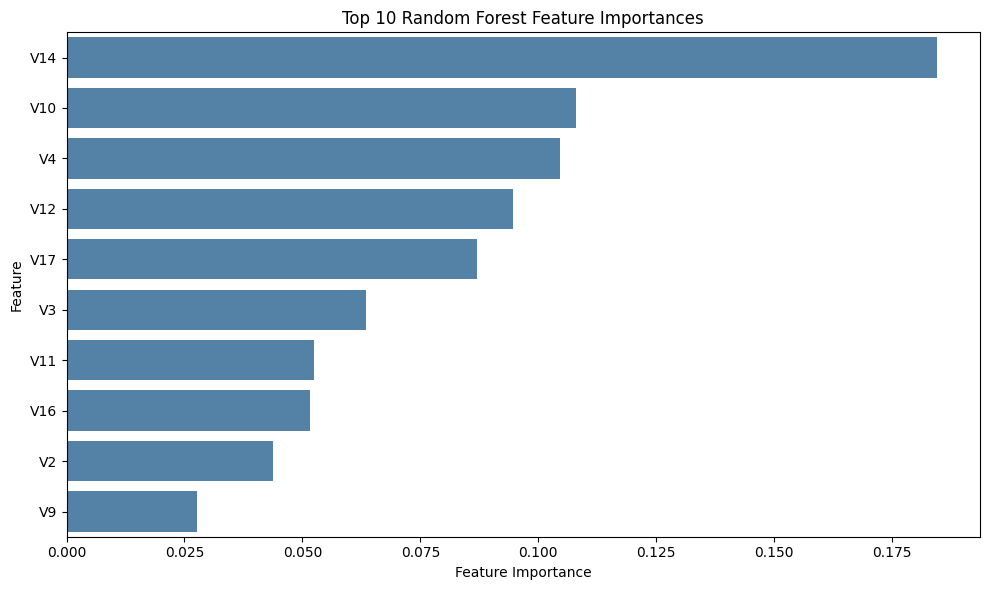

In [124]:

plt.figure(figsize=(10, 6))

top_features = importance_df.head(10)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [125]:

from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# Training data ka chhota stratified sample
X_sample, _, y_sample, _ = train_test_split(
    X_train_final,
    y_train_final,
    train_size=0.20,
    stratify=y_train_final,
    random_state=42
)

# Permutation importance
perm_result = permutation_importance(
    rf_model,
    X_sample,
    y_sample,
    scoring="average_precision",
    n_repeats=2,
    random_state=42,
    n_jobs=1
)

perm_df = pd.DataFrame({
    "Feature": X_sample.columns,
    "Importance": perm_result.importances_mean
})

perm_df = perm_df.sort_values(
    "Importance",
    ascending=False
)

display(perm_df.head(10))


,Feature,Importance
4,V4,0.071974
26,V26,0.022259
17,V17,0.019699
11,V11,0.018945
9,V9,0.014953
2,V2,0.010941
3,V3,0.010826
1,V1,0.010109
10,V10,0.009506
0,Time,0.008878


In [126]:

from sklearn.inspection import permutation_importance

gb_perm = permutation_importance(
    gb_model,
    X_sample,
    y_sample,
    scoring="average_precision",
    n_repeats=2,
    random_state=42,
    n_jobs=1
)

gb_importance_df = pd.DataFrame({
    "Feature": X_sample.columns,
    "Importance": gb_perm.importances_mean
})

gb_importance_df = gb_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Gradient Boosting Top 10 Features:")
display(gb_importance_df.head(10))


Gradient Boosting Top 10 Features:


,Feature,Importance
10,V10,0.413473
14,V14,0.235097
4,V4,0.070278
8,V8,0.031302
26,V26,0.027905
12,V12,0.013898
29,Amount,0.012475
19,V19,0.010361
28,V28,0.009229
7,V7,0.007864


In [127]:

from sklearn.base import clone

final_model = clone(gb_model)

final_model.fit(X_train, y_train)

final_threshold = 0.40

print("Final Gradient Boosting model trained!")
print("Selected threshold:", final_threshold)
print("Training rows:", X_train.shape[0])


Final Gradient Boosting model trained!
Selected threshold: 0.4
Training rows: 227845


In [128]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Final test fraud scores
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Validation se selected threshold
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

print("FINAL TEST RESULTS")

print("Precision:", precision_score(
    y_test, test_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_test, test_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, test_predictions, zero_division=0
))

print("Average Precision:", average_precision_score(
    y_test, test_probabilities
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, test_predictions,
    target_names=["Normal", "Fraud"],
    zero_division=0
))


FINAL TEST RESULTS
Precision: 0.872093023255814
Recall: 0.7653061224489796
F1 Score: 0.8152173913043478
Average Precision: 0.8076013310681649

Confusion Matrix:
[[56853    11]
 [   23    75]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.87      0.77      0.82        98

    accuracy                           1.00     56962
   macro avg       0.94      0.88      0.91     56962
weighted avg       1.00      1.00      1.00     56962



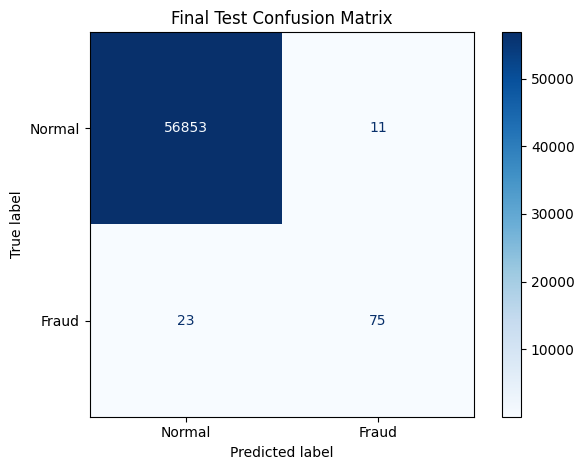

In [129]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Normal", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Final Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [130]:

import joblib

model_package = {
    "model": final_model,
    "threshold": final_threshold,
    "features": X_train.columns.tolist()
}

joblib.dump(
    model_package,
    "credit_card_fraud_model.joblib"
)

print("Model saved successfully!")


Model saved successfully!


In [131]:

from google.colab import files

files.download("credit_card_fraud_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>